In [77]:
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_csv('../data/proccessed_sunspots.csv', index_col=0)

In [3]:
df = df.rename(columns={'Month': 'ds', 'Sunspots': 'y'})
df['unique_id'] = 'Sunspot'
df = df[['unique_id', 'ds', 'y']]

In [4]:
train, test = train_test_split(df, test_size=0.2, shuffle=False)

In [5]:
train

,unique_id,ds,y
0,Sunspot,1749-01-01,58.0
1,Sunspot,1749-02-01,62.6
2,Sunspot,1749-03-01,70.0
3,Sunspot,1749-04-01,55.7
4,Sunspot,1749-05-01,85.0
...,...,...,...
2251,Sunspot,1936-08-01,87.0
2252,Sunspot,1936-09-01,76.0
2253,Sunspot,1936-10-01,89.0
2254,Sunspot,1936-11-01,115.4


# STL-декомпозиция

In [6]:
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

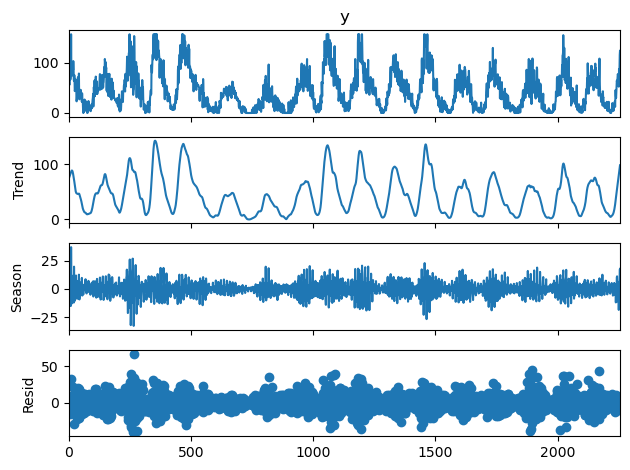

In [7]:
stl = STL(train['y'], period=12)
result = stl.fit()
result.plot();

В данном ряде отсутствует тренд, однако присутствует сезонность. Характер ошибок случаен

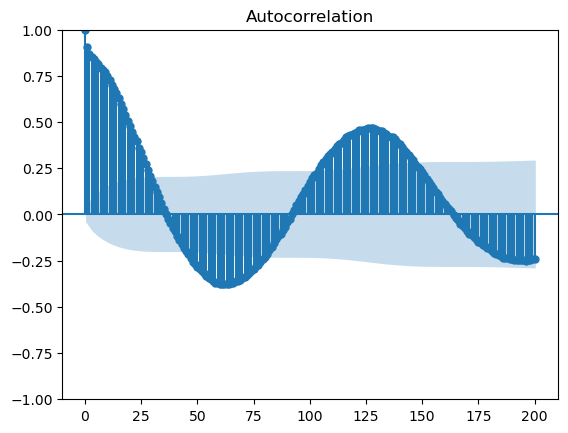

In [8]:
plot_acf(train['y'], lags=200);

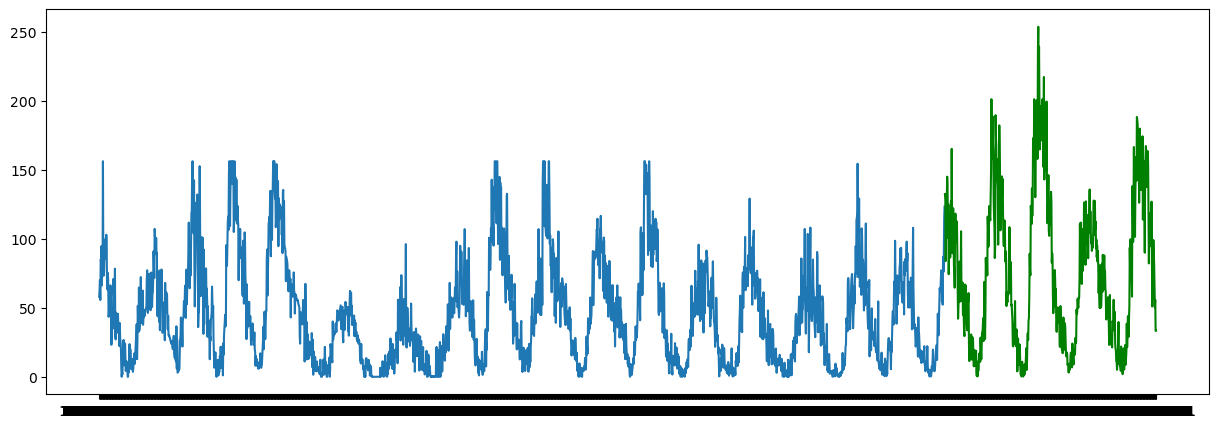

In [12]:
plt.figure(figsize=(15, 5))
plt.plot(train['ds'], train['y'], label='train')
plt.plot(test['ds'], test['y'], c='g', label='test')

# ExponentialSmoothing

In [9]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [54]:
model = ExponentialSmoothing(
    train['y'],
    trend='add',
    seasonal='add',
    seasonal_periods=126
)

In [58]:
model_fit = model.fit(method='Powell')

In [59]:
pred = model_fit.forecast(test.shape[0])

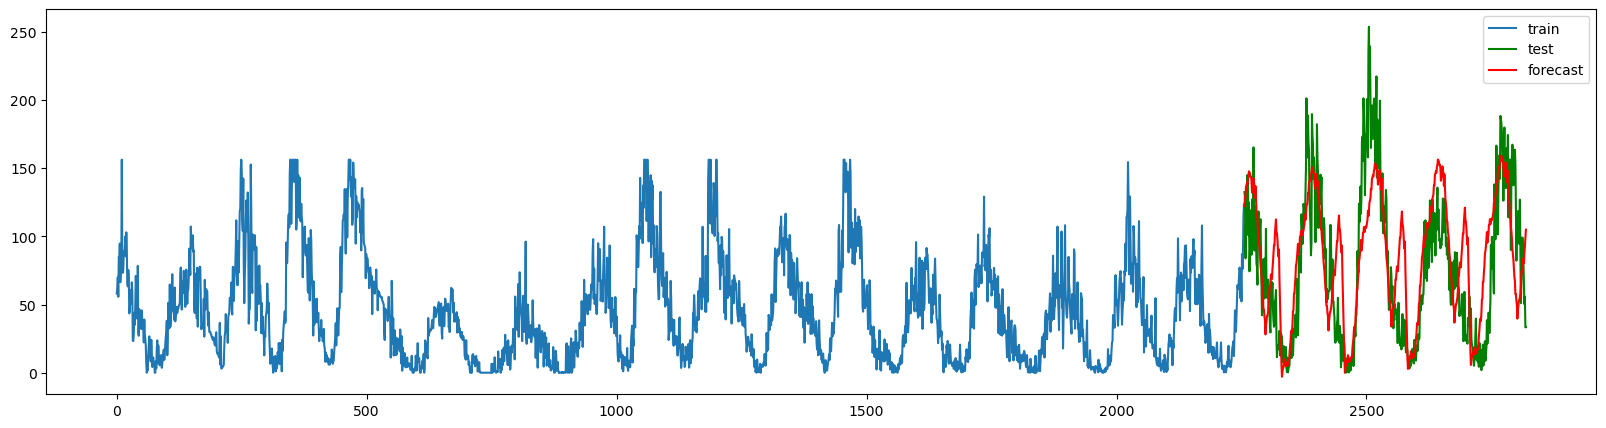

In [62]:
plt.figure(figsize=(20, 5))
train['y'].plot(label='train')
test['y'].plot(label='test', c='g')
pred.plot(label='forecast', c='r')
plt.legend()

In [69]:
residuals = (pred - test['y'])

In [70]:
residuals

2256   -10.354528
2257     0.291321
2258    44.493993
2259    27.097330
2260    20.905752
          ...    
2815    13.965411
2816    37.534179
2817    36.757206
2818    65.085744
2819    71.509290
Length: 564, dtype: float64

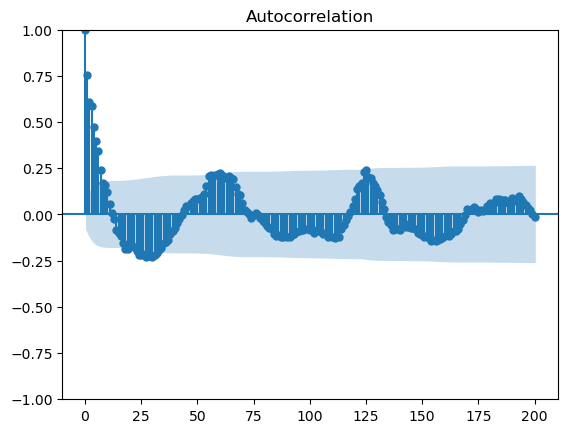

In [71]:
plot_acf(residuals ** 2, lags=200);

# GARCH

In [73]:
from arch import arch_model

In [74]:
garch = arch_model(residuals.dropna(), vol="Garch", p=1, q=1)
garch_fit = garch.fit()

Iteration:      1,   Func. Count:      6,   Neg. LLF: 2960.0261461576756
Iteration:      2,   Func. Count:     12,   Neg. LLF: 2721.1676148445185
Iteration:      3,   Func. Count:     17,   Neg. LLF: 2721.0089876622233
Iteration:      4,   Func. Count:     22,   Neg. LLF: 2720.86645570817
Iteration:      5,   Func. Count:     27,   Neg. LLF: 2720.0475366511864
Iteration:      6,   Func. Count:     32,   Neg. LLF: 2717.7471517165764
Iteration:      7,   Func. Count:     37,   Neg. LLF: 2716.428041422234
Iteration:      8,   Func. Count:     42,   Neg. LLF: 2715.4607662502613
Iteration:      9,   Func. Count:     47,   Neg. LLF: 3481.7485474485084
Iteration:     10,   Func. Count:     54,   Neg. LLF: 2715.0657790417927
Iteration:     11,   Func. Count:     59,   Neg. LLF: 2715.0282451153566
Iteration:     12,   Func. Count:     64,   Neg. LLF: 2714.998360325775
Iteration:     13,   Func. Count:     69,   Neg. LLF: 2714.997895233085
Iteration:     14,   Func. Count:     74,   Neg. LLF: 27

In [75]:
garch_forecast = garch_fit.forecast(horizon=len(test))
garch_forecast

In [78]:
variance = garch_forecast.variance.values[-1]
sigma = np.sqrt(variance)

In [79]:
z = 1.96

upper = sigma * z
lower = -sigma * z

In [81]:
upper_bound = pred.values + upper
lower_bound = pred.values + lower

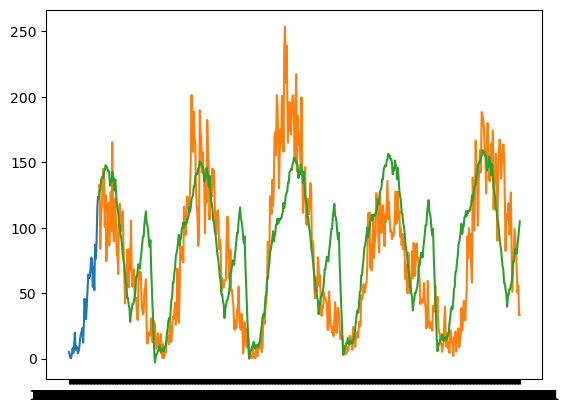

In [82]:
plt.plot(train['ds'][-40:], train['y'][-40:])
plt.plot(test['ds'], test['y'])
plt.plot(test['ds'], pred.values)

Text(0.5, 1.0, 'Хольт-Винтерс + GARCH')

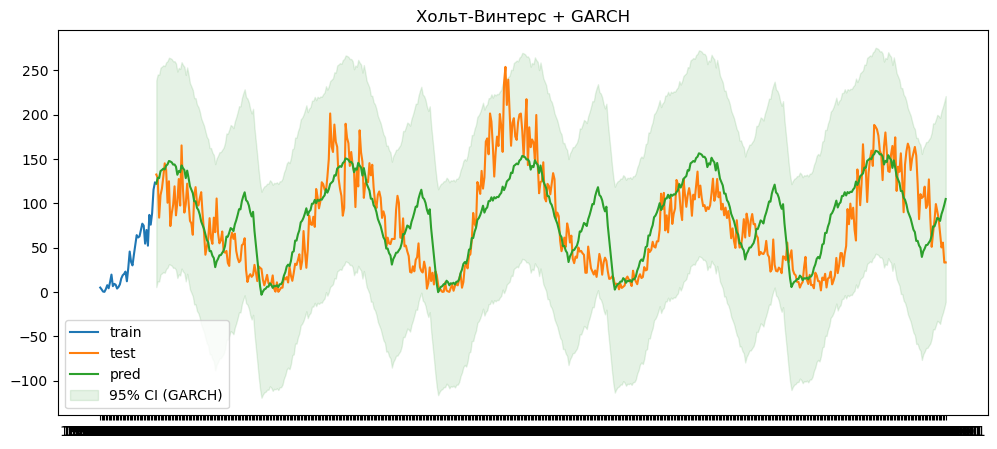

In [83]:
plt.figure(figsize=(12,5))

plt.plot(train['ds'][-40:], train['y'][-40:])
plt.plot(test['ds'], test['y'])
plt.plot(test['ds'], pred.values)

plt.fill_between(
    test['ds'],
    lower_bound,
    upper_bound,
    alpha=0.1,
    color='green'
)

plt.legend(['train', 'test', 'pred', '95% CI (GARCH)'])
plt.title("Хольт-Винтерс + GARCH")